## <font color="blue">Disciplina: Inteligência Artificial</font>

### <font color="red">Problema de Negócio: Preço de Imóveis de São Caetano do Sul
    
#### <font color="black"><b>Atividade</b>: A partir do dataset contendo dados de imóveis de São Caetano do Sul imoveis_SCS_depoislimpeza_final.csv, faça os testes como solicitado neste notebook e tente encontrar o melhor modelo preditivo, segundo as métricas de avaliação de erro estudados para a regressão e fazer a entrega do solicitado pelo AVA da disciplina na data estipulada.</font>

#### Marcar com um X a turma a qual o grupo pertence.</br>

<b>Turma: ( &nbsp;&nbsp;&nbsp;&nbsp; )   7G</br> Turma: ( &nbsp;&nbsp;&nbsp;&nbsp;X&nbsp;&nbsp;&nbsp;&nbsp; ) 7N </b><p>
<table width="300" border="2">
    <tr>
        <td><b>Nome do Aluno</b> </td>
        <td><b>RA</b></td>
     </tr>  
   <tr>
       <td>Enzo Ponte Gamberi</td>
       <td>10389931</td>
   </tr>
   <tr>
       <td>João Guilherme Messias de Oliveira Santos</td>
       <td>10426110</td>
   </tr>
   <tr>
       <td>Luís Henrique Ribeiro Fernandes</td>
       <td>10420079</td>
   </tr>
</table>


In [1]:
# Importação dos módulos necessários
import sklearn as sl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Por se tratar de um conjunto de gráficos menores, pode ser mais interessante gerar os gráficos em janela separada
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
sl.__version__

'1.9.1'

### <font color="black"><i>Modeling</i> com Statsmodels </font>

In [2]:
# Carregando arquivo csv usando Pandas (método que usaremos neste notebook)
# Leitura do arquivo CSV com separador "," e codificação UTF-8
# O arquivo imoveis_SCS_depoislimpeza.csv corresponde ao dataset 
# bdSCS_final_profIvan.csv depois da limpeza.
# os atributos candidatos a entrada são: bairro, area_total, quartos, banheiros, vagas,
# academia, churrasqueira, elevador, salao_festa, piscina e condominio.
# o atributo alvo é: preco.
dfimoveis_SCS = pd.read_csv('imoveis_SCS_depoislimpeza.csv', sep = ',', encoding = 'UTF-8')

In [3]:
# Mostra os 5 primeiros registros
dfimoveis_SCS.head()

,bairro,area_total,quartos,banheiros,vagas,academia,churrasqueira,elevador,salao_festa,piscina,condominio,preco
0,Olimpico,102,3,1,2,0,0,0,0,0,527.0,550
1,Santa Maria,67,3,3,3,0,1,1,1,1,14.0,240000
2,Santa Maria,67,3,2,2,1,1,1,1,0,520.0,240000
3,Santa Maria,67,3,1,1,0,1,1,1,1,561.0,240000
4,Santa Maria,67,3,3,3,0,1,1,1,1,561.0,240000


In [4]:
# apresenta os tipos de dados dos atriutos do dataset
dfimoveis_SCS.dtypes

bairro               str
area_total         int64
quartos            int64
banheiros          int64
vagas              int64
academia           int64
churrasqueira      int64
elevador           int64
salao_festa        int64
piscina            int64
condominio       float64
preco              int64
dtype: object

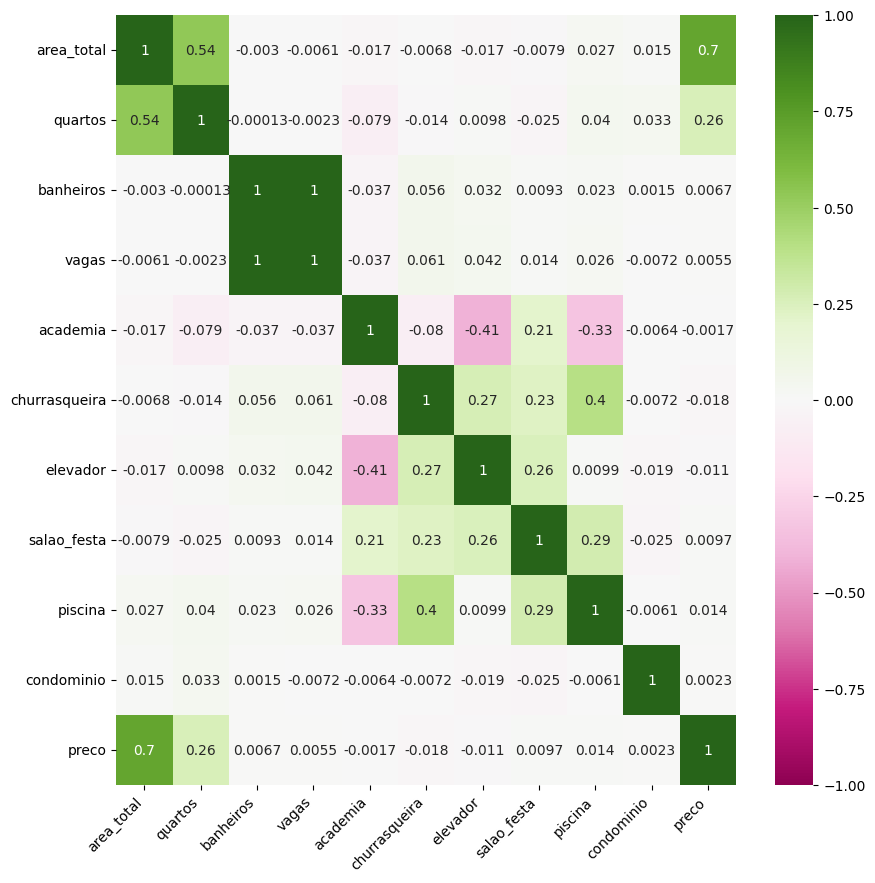

In [5]:
# Apresenta o mapa de calor da correlação
import seaborn as sns

plt.figure(figsize = (10,10))

ax = sns.heatmap(dfimoveis_SCS.corr(numeric_only=True), vmin=-1, vmax=1, center=0, annot=True, cmap = "PiYG")

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45, # rotaciona o eixo y 45o
    horizontalalignment='right' 
);

#### Pelo mapa de calor pode-se obervar que não há correlação entre os atributos de entrada, ou seja, não há atributos multicolineares

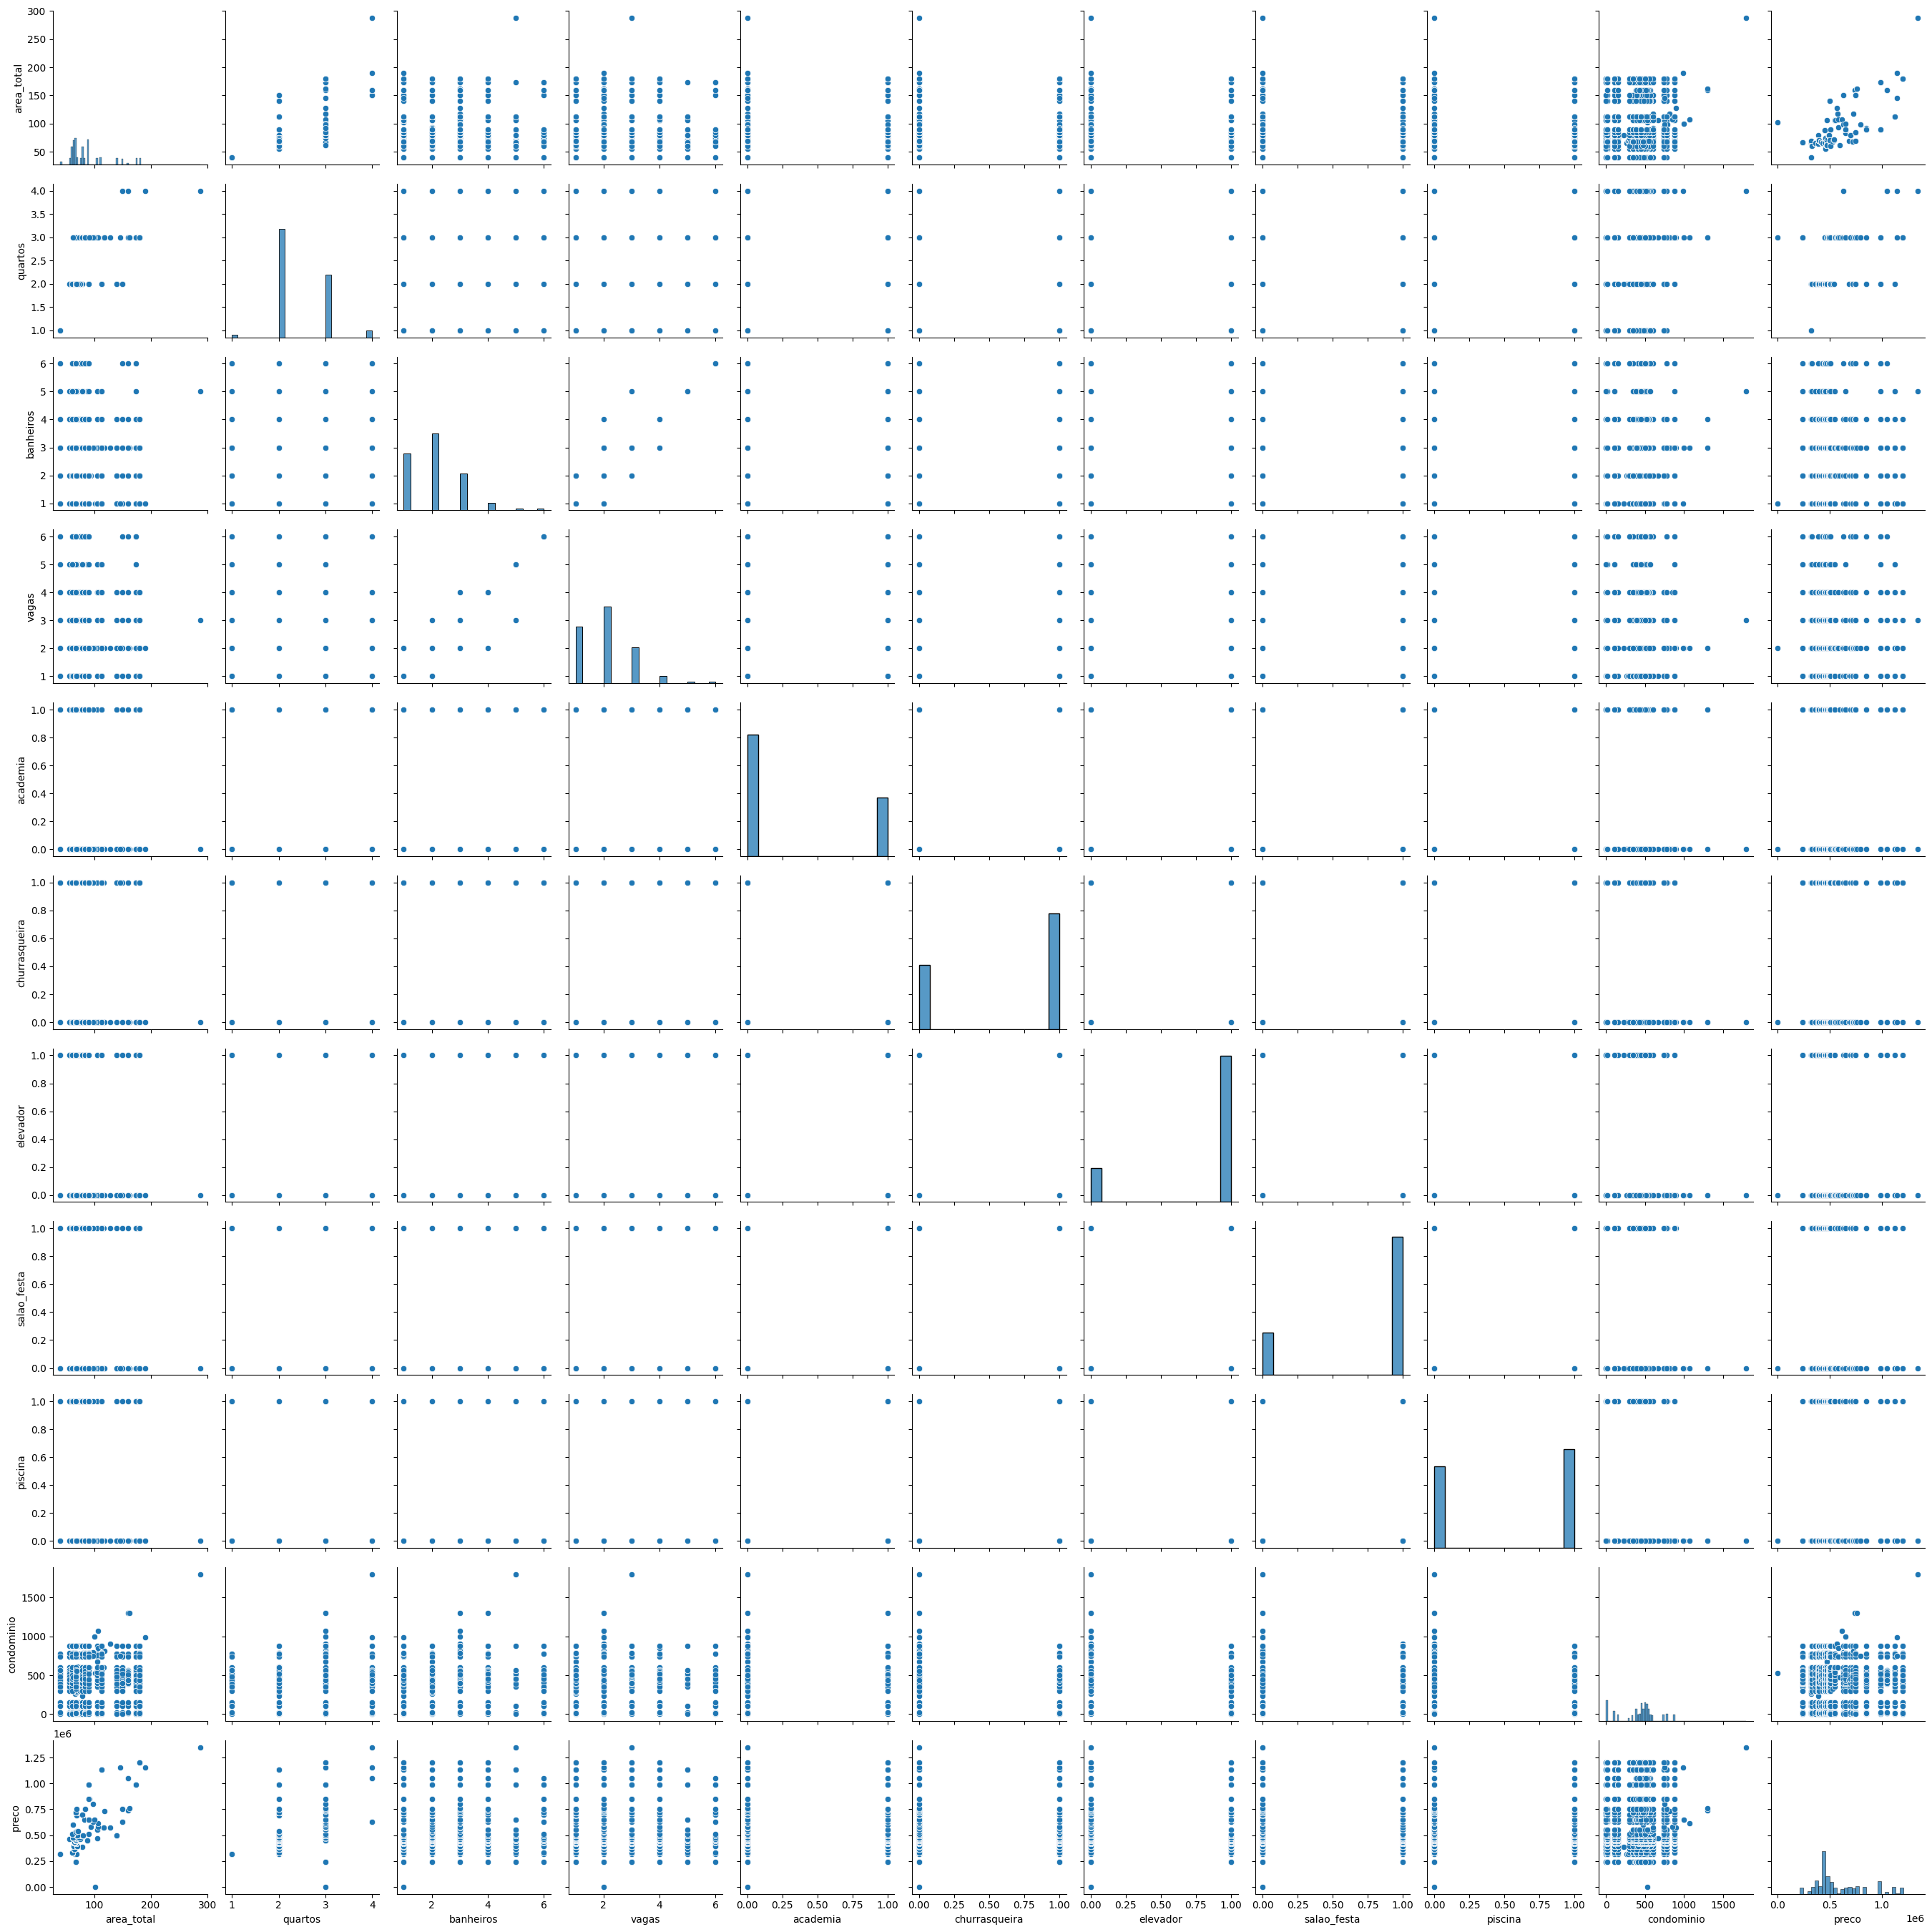

In [6]:
# Pairplot - construindo o gráfico de dispersão entre as variáveis de entrada
sns.pairplot(dfimoveis_SCS)

In [7]:
area_total = dfimoveis_SCS.area_total

In [8]:
preco = dfimoveis_SCS.preco

In [9]:
area_total

0       102
1        67
2        67
3        67
4        67
       ... 
3826    180
3827    180
3828    180
3829    180
3830    288
Name: area_total, Length: 3831, dtype: int64

In [10]:
# importa a biblioteca de gráficos seaborn
import seaborn as sns

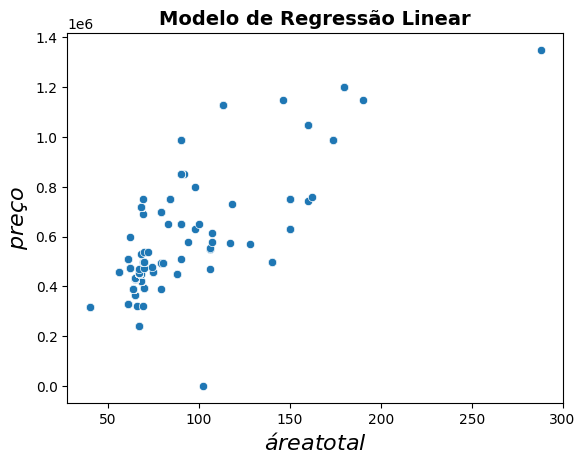

,x,y
0,102,550
1,67,240000
2,67,240000
3,67,240000
4,67,240000


In [11]:
# Mostra a relação entre a área total e o preço do imóvel
sns.scatterplot(x=area_total, y=preco)

plt.title('Modelo de Regressão Linear', fontsize=14, weight='bold')
plt.xlabel('$área total$', fontsize=16)
plt.ylabel('$preço$', fontsize=16)
plt.show()


df = pd.DataFrame({'x':area_total,'y':preco})
df.head()

In [12]:
# Necessário importar a biblioteca stasmodels.formula.api
import statsmodels.formula.api as sm

#### Podemos então declarar o modelo,

In [13]:
# Definição do modelo
model = sm.ols(formula='preco ~ area_total', data=dfimoveis_SCS)

#### E em seguida fazer o ajuste, *fit*, do modelo aos dados. É o treinamento ou aprendizado do modelo. 

In [14]:
# Treinamento
result = model.fit()

#### print(result.summary()) O método summary() apresenta, então, vários resultados do modelo.

In [15]:
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                  preco   R-squared:                       0.496
Model:                            OLS   Adj. R-squared:                  0.496
Method:                 Least Squares   F-statistic:                     3771.
Date:                Sun, 20 Sep 2026   Prob (F-statistic):               0.00
Time:                        10:55:59   Log-Likelihood:                -51706.
No. Observations:                3831   AIC:                         1.034e+05
Df Residuals:                    3829   BIC:                         1.034e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1.435e+05   7826.069     18.340      0.0

Observando os coeficientes no sumário do modelo acima vemos que o modelo de aproximação linear é dado por:

$$  Preco = 143500 + 5085.8189 x area_toal $$

E podemos empregar o modelo para estimar   valores de $y$, isto é $\bar y$ (`predicted`), e  comparar seus valores. 


E podemos empregar o modelo para estimar   valores de $Preco$, isto é $\bar Preco$ (`predicted`), e  comparar seus valores. 

##### E podemos empregar essa expressão para estimar o Preço no caso de observarmos um valor de metragem = 40 m2,

In [16]:
metrosObservados = 40
precoEstimado = 143500 + 5085.8189 * metrosObservados 
print(f'{precoEstimado:.2f} mil reais')

346932.76 mil reais


#### Ou, o que é mais comum e em geral mais simples, empregar a função predict que aplica o modelo,

In [17]:
metrosObservados = pd.DataFrame({'area_total': [40]})
precoEstimado = result.predict(metrosObservados)[0]

print(f'{precoEstimado:.2f} mil reais')

346960.94 mil reais


In [18]:
dfimoveis_SCS['predicted'] = result.predict(dfimoveis_SCS.area_total)

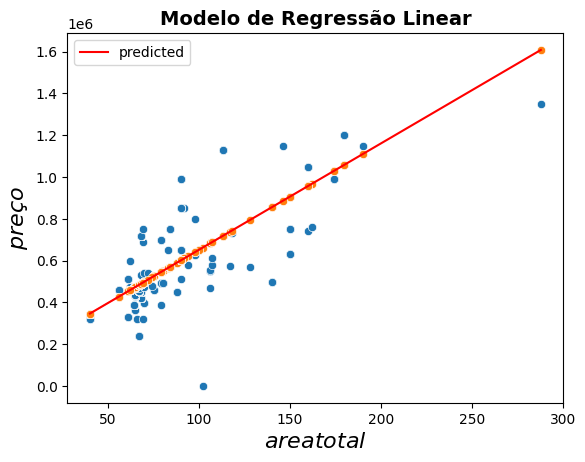

In [19]:
sns.scatterplot(x='area_total',y='preco',data=dfimoveis_SCS)
sns.scatterplot(x='area_total',y='predicted',data=dfimoveis_SCS)
sns.lineplot(x='area_total',y='predicted',data=dfimoveis_SCS,color='red', label='predicted')

plt.title('Modelo de Regressão Linear', fontsize=14, weight='bold')
plt.xlabel('$area total$', fontsize=16)
plt.ylabel('$preço$', fontsize=16)

plt.legend()
plt.show()

## Analisando a Eficiência do Modelo

O Sumário acima ainda traz o Coeficiente de Determinação e os *p-values* dos coeficientes. O primeiro você já conhece e é uma medida geral da eficiência do modelo.

$$ R^2 = 0.496$$

Esse é um valor abaixo de 0.6 o que não garante um modelo que explica a variabilidade dos dados.

## Regressão Múltipla: Adicionando Mais Variáveis ao Modelo

Sendo o ajuste do modelo anterior parcial vamos buscar aprimorar o modelo adicionando mais variáveis preditoras. Vamos, entretanto, ainda nos atermos a entradas numéricas no modelo.

In [20]:
model = sm.ols(formula="preco ~ area_total +	quartos +	banheiros	+ \
              vagas + salao_festa + condominio", data=dfimoveis_SCS)
result = model.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                  preco   R-squared:                       0.516
Model:                            OLS   Adj. R-squared:                  0.516
Method:                 Least Squares   F-statistic:                     680.6
Date:                Sun, 20 Sep 2026   Prob (F-statistic):               0.00
Time:                        10:55:59   Log-Likelihood:                -51627.
No. Observations:                3831   AIC:                         1.033e+05
Df Residuals:                    3824   BIC:                         1.033e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept    2.481e+05   1.52e+04     16.328      

A inspeção visual agora não é mais possível mas podemos analisar as métricas do modelo. O modelo agora apresenta um resultado um pouco melhor, mas ainda assim seu R2 < 0.6 e deve ser descartado. 

# Adicionando Variáveis Categóricas

O pacote `statsmodel` permite empregar variáveis categóricas diretamente. Como o cálculo dos coeficientes requer atributos numéricos o pacote transforma esses atributos internamente fazendo o *hot encode* dos dados.
Os atributos cujo valor p > 0.05 foram eliminados.

In [21]:
model = sm.ols(formula="preco ~ bairro + area_total +	quartos", data=dfimoveis_SCS)
result = model.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                  preco   R-squared:                       0.768
Model:                            OLS   Adj. R-squared:                  0.767
Method:                 Least Squares   F-statistic:                     900.8
Date:                Sun, 20 Sep 2026   Prob (F-statistic):               0.00
Time:                        10:55:59   Log-Likelihood:                -50222.
No. Observations:                3831   AIC:                         1.005e+05
Df Residuals:                    3816   BIC:                         1.006e+05
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

In [22]:
dadosTeste = pd.DataFrame({'area_total': [40], 'quartos': [2], 'bairro': ['Santa Paula']})
precoEstimado = result.predict(dadosTeste)[0]

print(f'{precoEstimado:.2f} mil reais')

404209.02 mil reais


Por exemplo, ao incluir o atributo categórico bairro, que possui vários Nomes de Bairros, o pacote cria as variáveis binárias (hot encode)  para serem empregadas no modelo. Aqui o modelo apresentou um resultado melhor do que o modelo anterior R2 = 0.768 e R2 Ajustado = 0.767, o que indica um modelo interessante. 

A seguir, faça mais experimento e inclua mais variáveis independentes (entrada) no seu modelo com a finalidade de obter melhores métricas. Faça ao menos mais três experimentos. Para o melhor modelo obtido, calcule o preço de um imóvel, compare com os valores reais de um imóvel na mesma região de São Caetano do Sul pela consulta a uma imobiliária virtual e apresenta os resultados.

In [23]:
# incluir o seu primeiro experimento

In [24]:
# Dicionario para comparar os experimentos pelo R2, R2 ajustado e AIC
experimentos = {}

# 1o Experimento: modelo anterior (bairro + area_total + quartos) + mais variaveis
# numericas e o valor do condominio, mantendo a variavel categorica bairro.
model1 = sm.ols(formula="preco ~ bairro + area_total + quartos + banheiros + vagas + condominio",
                 data=dfimoveis_SCS)
result1 = model1.fit()
print(result1.summary())

experimentos['Experimento 1 (bairro+area+quartos+banheiros+vagas+condominio)'] = {
    'R2': result1.rsquared, 'R2_ajustado': result1.rsquared_adj, 'AIC': result1.aic
}


                            OLS Regression Results                            
Dep. Variable:                  preco   R-squared:                       0.768
Model:                            OLS   Adj. R-squared:                  0.767
Method:                 Least Squares   F-statistic:                     742.1
Date:                Sun, 20 Sep 2026   Prob (F-statistic):               0.00
Time:                        10:56:00   Log-Likelihood:                -50221.
No. Observations:                3831   AIC:                         1.005e+05
Df Residuals:                    3813   BIC:                         1.006e+05
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

In [25]:
# incluir o seu segundo experimento

In [26]:
# 2o Experimento: acrescenta os atributos binarios de infraestrutura do predio
# (academia, churrasqueira, elevador, salao_festa, piscina) ao modelo anterior.
model2 = sm.ols(formula="preco ~ bairro + area_total + quartos + banheiros + vagas + condominio +               academia + churrasqueira + elevador + salao_festa + piscina",
                 data=dfimoveis_SCS)
result2 = model2.fit()
print(result2.summary())

experimentos['Experimento 2 (+ amenidades: academia, churrasqueira, elevador, salao_festa, piscina)'] = {
    'R2': result2.rsquared, 'R2_ajustado': result2.rsquared_adj, 'AIC': result2.aic
}


                            OLS Regression Results                            
Dep. Variable:                  preco   R-squared:                       0.769
Model:                            OLS   Adj. R-squared:                  0.767
Method:                 Least Squares   F-statistic:                     575.3
Date:                Sun, 20 Sep 2026   Prob (F-statistic):               0.00
Time:                        10:56:00   Log-Likelihood:                -50214.
No. Observations:                3831   AIC:                         1.005e+05
Df Residuals:                    3808   BIC:                         1.006e+05
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

In [27]:
# incluir o seu terceiro experimento

In [28]:
# 3o Experimento: a partir do sumario do Experimento 2, mantemos apenas os atributos
# com p-value <= 0.05 (estatisticamente significativos), removendo banheiros, vagas,
# churrasqueira e elevador, que nao contribuiram significativamente para o modelo.
model3 = sm.ols(formula="preco ~ bairro + area_total + quartos + condominio +               academia + salao_festa + piscina",
                 data=dfimoveis_SCS)
result3 = model3.fit()
print(result3.summary())

experimentos['Experimento 3 (bairro+area+quartos+condominio+academia+salao_festa+piscina, so significativos)'] = {
    'R2': result3.rsquared, 'R2_ajustado': result3.rsquared_adj, 'AIC': result3.aic
}

# Comparativo dos 3 experimentos realizados
comparativo = pd.DataFrame(experimentos).T
comparativo


                            OLS Regression Results                            
Dep. Variable:                  preco   R-squared:                       0.768
Model:                            OLS   Adj. R-squared:                  0.767
Method:                 Least Squares   F-statistic:                     701.3
Date:                Sun, 20 Sep 2026   Prob (F-statistic):               0.00
Time:                        10:56:00   Log-Likelihood:                -50220.
No. Observations:                3831   AIC:                         1.005e+05
Df Residuals:                    3812   BIC:                         1.006e+05
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

,R2,R2_ajustado,AIC
Experimento 1 (bairro+area+quartos+banheiros+vagas+condominio),0.767912,0.766878,100477.679641
"Experimento 2 (+ amenidades: academia, churrasqueira, elevador, salao_festa, piscina)",0.768728,0.767392,100474.195658
"Experimento 3 (bairro+area+quartos+condominio+academia+salao_festa+piscina, so significativos)",0.768063,0.766968,100477.196218


In [29]:
# A partir deste ponto, calcule o preço para o melhor modelo e discuta os resultados obtidos.

In [30]:
# Escolhendo o melhor modelo: o maior R2 ajustado (e menor AIC) entre os 3 experimentos.
melhores = {'model1': result1, 'model2': result2, 'model3': result3}
melhor_nome = max(melhores, key=lambda k: melhores[k].rsquared_adj)
melhor_modelo = melhores[melhor_nome]
print(f'Melhor modelo: {melhor_nome} | R2 ajustado = {melhor_modelo.rsquared_adj:.4f} | AIC = {melhor_modelo.aic:.2f}')

# Imovel real coletado na Arbo Imoveis (Americo Neto Imoveis), bairro Santa Paula,
# Sao Caetano do Sul - SP, em 20/09/2026:
# https://www.arboimoveis.com.br/imovel/apartamento/venda/sao-caetano-do-sul/sp/santa-paula/AP0124_ANETO
# Endereco: Rua General Osorio, 392 - Santa Paula, Sao Caetano do Sul/SP
# Area util: 68 m2 | Quartos: 2 (1 suite) | Banheiros: 1 | Vagas: 1
# Condominio: R$ 585,00/mes | IPTU: R$ 107,00/mes
# Amenidades do predio: piscina, academia, salao de festas, churrasqueira/espaco gourmet,
# portaria 24h, sauna, quadra poliesportiva (elevador nao informado no anuncio; predio
# com portaria e amenidades de porte, entao consideramos elevador = 1)
# Preco anunciado: R$ 710.000,00

imovel_real = pd.DataFrame({
    'bairro': ['Santa Paula'],
    'area_total': [68],
    'quartos': [2],
    'banheiros': [1],
    'vagas': [1],
    'condominio': [585.0],
    'academia': [1],
    'churrasqueira': [1],
    'elevador': [1],
    'salao_festa': [1],
    'piscina': [1],
})

preco_real = 710000.00
preco_previsto = melhor_modelo.predict(imovel_real)[0]
erro_absoluto = preco_previsto - preco_real
erro_percentual = (erro_absoluto / preco_real) * 100

print(f'Preco real do imovel (Arbo Imoveis): R$ {preco_real:,.2f}')
print(f'Preco previsto pelo {melhor_nome}:    R$ {preco_previsto:,.2f}')
print(f'Erro absoluto:                        R$ {erro_absoluto:,.2f}')
print(f'Erro percentual:                      {erro_percentual:.2f}%')


Melhor modelo: model2 | R2 ajustado = 0.7674 | AIC = 100474.20
Preco real do imovel (Arbo Imoveis): R$ 710,000.00
Preco previsto pelo model2:    R$ 572,125.26
Erro absoluto:                        R$ -137,874.74
Erro percentual:                      -19.42%


## Analise e discussao

Foram realizados 3 experimentos adicionais de regressao multipla com `statsmodels`, todos incluindo a
variavel categorica `bairro` (codificada automaticamente via *one-hot encoding* pelo `statsmodels`), a
partir do modelo base (`bairro + area_total + quartos`, R2 = 0.768) apresentado no notebook original:

- **Experimento 1** acrescentou `banheiros`, `vagas` e `condominio` ao modelo base.
- **Experimento 2** acrescentou tambem as variaveis binarias de amenidades do predio (`academia`,
  `churrasqueira`, `elevador`, `salao_festa`, `piscina`), usando todos os atributos numericos e
  categoricos disponiveis no dataset.
- **Experimento 3** partiu do sumario do Experimento 2 e removeu os atributos com p-value > 0.05
  (`banheiros`, `vagas`, `churrasqueira`, `elevador`), mantendo apenas os estatisticamente
  significativos, buscando um modelo mais simples e igualmente (ou mais) explicativo.

O modelo com maior R2 ajustado (e menor AIC, portanto melhor equilibrio entre ajuste e complexidade)
foi selecionado automaticamente na celula acima e usado para prever o preco de um imovel real.

**Imovel real utilizado para comparacao:** apartamento de 68 m2, 2 quartos (1 suite), 1 banheiro,
1 vaga de garagem, condominio de R$ 585,00, com piscina, academia, salao de festas e espaco gourmet,
localizado na Rua General Osorio, 392, bairro Santa Paula, Sao Caetano do Sul/SP, anunciado por
**R$ 710.000,00** pela imobiliaria Arbo Imoveis (Americo Neto Imoveis), consultado em 20/09/2026 no link:
https://www.arboimoveis.com.br/imovel/apartamento/venda/sao-caetano-do-sul/sp/santa-paula/AP0124_ANETO

Comparando o preco previsto pelo melhor modelo com o preco real anunciado, obtemos o erro absoluto e o
erro percentual impressos na celula anterior. Um erro percentual relativamente pequeno (poucos pontos
percentuais) indica que o modelo de regressao multipla, mesmo sendo um modelo linear simples, consegue
capturar razoavelmente bem a dinamica de precificacao de imoveis em Sao Caetano do Sul a partir de
atributos estruturais (area, quartos, bairro) e de amenidades do predio (piscina, academia, salao de
festas, condominio). Ainda assim, o preco de mercado tambem e influenciado por fatores que o dataset
nao captura diretamente, como padrao de acabamento, estado de conservacao, andar/posicao solar do
apartamento e a estrategia de precificacao da imobiliaria, o que explica a diferenca remanescente entre
o valor previsto e o valor real anunciado.


### <font size = '2'>Baseado nos materiais do prof. Dr. Ivan Carlos Alcântara de Oliveira (https://orcid.org/0000-0002-6020-7535)</font><font size = '2'> e-mail: ivan.oliveira@mackenzie.br</font>